# Full-frame graphene HAADF random-mask inpainting

This notebook loads the graphene HAADF frame directly from HDF5, treats the clean 2048 × 2048 frame as ground truth, removes 90% of pixels with one fixed global mask, reconstructs overlapping 128 × 128 tiles with the trained `sem_nffa_all10` PnP-Flow prior, Hann-blends tile predictions, and evaluates only the synthetically missing pixels.

Mask convention: `known_mask=True` is observed and data-consistent; `missing_mask=True` is reconstructed.

In [1]:
from pathlib import Path
import json
import math
import os
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    repo_root = repo_root.parent
if not (repo_root / 'pnpflow').is_dir():
    raise RuntimeError('Open this notebook from the PnP-Flow repository or its notebooks/ directory.')
os.chdir(repo_root)

from pnpflow.utils import define_model

DATASET_NAME = 'sem_nffa_all10'
RUN_NAME = '20260713_112747_sem_nffa_all10_ot'
CHECKPOINT_PATH = repo_root / 'model' / DATASET_NAME / 'ot' / RUN_NAME / 'model_final.pt'

HAADF_H5 = Path.home() / 'projects/microscopic_inpainting/content/graphene_2.h5'
HAADF_DATASET_PATH = 'Measurement_000/Channel_000/HAADF/HAADF'
HAADF_X_PATH = 'Measurement_000/Channel_000/HAADF/x'
HAADF_Y_PATH = 'Measurement_000/Channel_000/HAADF/y'

# Same inference variables as nffa_full_raw_random_inpainting.ipynb.
MISSING_FRACTION = 0.50
MASK_SEED = 42
NOISE_SEED = 0
NOISE_STD = 0.01
STEPS_PNP = 100
NUM_SAMPLES = 5
LR_PNP = 1.0
ALPHA = 0.01
TILE_SIZE = 128
TILE_STRIDE = 64
INFERENCE_BATCH_SIZE = 640
USE_MULTI_GPU = True
SELECTED_TILE_INDEX = None

frame_name = f'{HAADF_H5.stem}_{HAADF_DATASET_PATH.split("/")[0]}'
OUTPUT_DIR = repo_root / 'results' / DATASET_NAME / 'ot' / 'haadf_graphene_full_random_inpainting' / frame_name
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT_PATH.is_file(), f'Checkpoint not found: {CHECKPOINT_PATH}'
assert HAADF_H5.is_file(), f'Graphene HDF5 file not found: {HAADF_H5}'
print(f'Repository: {repo_root}')
print(f'Checkpoint: {CHECKPOINT_PATH}')
print(f'HAADF HDF5: {HAADF_H5}')
print(f'HAADF dataset: {HAADF_DATASET_PATH}')
print(f'Output directory: {OUTPUT_DIR}')

/data2/marci/bselvaku/conda/envs/torchlearn/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow
Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10/ot/20260713_112747_sem_nffa_all10_ot/model_final.pt
HAADF HDF5: /home/bselvaku/projects/microscopic_inpainting/content/graphene_2.h5
HAADF dataset: Measurement_000/Channel_000/HAADF/HAADF
Output directory: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/haadf_graphene_full_random_inpainting/graphene_2_Measurement_000


In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('This full-frame PnP benchmark requires a CUDA GPU.')

torch.manual_seed(0)
torch.cuda.manual_seed_all(0)

class ModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = TILE_SIZE

model, _ = define_model(ModelArgs())
state_dict = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.to(device).eval()

gpu_ids = list(range(torch.cuda.device_count()))
if USE_MULTI_GPU and len(gpu_ids) > 1:
    model = torch.nn.DataParallel(model, device_ids=gpu_ids, output_device=gpu_ids[0])
    print(f'Multi-GPU inference enabled on {len(gpu_ids)} GPUs: {gpu_ids}')
else:
    print(f'Single-GPU inference on {torch.cuda.get_device_name(0)}')
print(f'Primary device: {device}')

Multi-GPU inference enabled on 4 GPUs: [0, 1, 2, 3]
Primary device: cuda:0


In [3]:
# Load the HAADF frame and physical coordinate axes directly from HDF5.
with h5py.File(HAADF_H5, 'r') as handle:
    if HAADF_DATASET_PATH not in handle:
        raise KeyError(f'HDF5 dataset not found: {HAADF_DATASET_PATH}')
    raw_haadf = handle[HAADF_DATASET_PATH][()].astype(np.float32)
    x_axis = handle[HAADF_X_PATH][()].astype(np.float64) if HAADF_X_PATH in handle else None
    y_axis = handle[HAADF_Y_PATH][()].astype(np.float64) if HAADF_Y_PATH in handle else None

if raw_haadf.ndim != 2 or not np.isfinite(raw_haadf).all():
    raise ValueError(f'Expected a finite 2D HAADF frame, got {raw_haadf.shape}')
height, width = raw_haadf.shape
if height < TILE_SIZE or width < TILE_SIZE:
    raise ValueError(f'HAADF frame {raw_haadf.shape} is smaller than TILE_SIZE={TILE_SIZE}.')

# Controlled synthetic benchmark: the clean frame is available, so normalize from
# the complete source using the same 1st/99th-percentile mapping used for SEM data.
low, high = np.percentile(raw_haadf, (1, 99))
if not high > low:
    raise ValueError('The HAADF frame has no usable percentile intensity range.')
raw_clipped = np.clip(raw_haadf, low, high).astype(np.float32)
raw_norm = (2.0 * (raw_clipped - low) / (high - low) - 1.0).astype(np.float32)

mask_rng = np.random.default_rng(MASK_SEED)
missing_mask = mask_rng.random(raw_haadf.shape) < MISSING_FRACTION
known_mask = ~missing_mask
noise_rng = np.random.default_rng(NOISE_SEED)
known_noise = noise_rng.normal(0.0, NOISE_STD, raw_haadf.shape).astype(np.float32)
observed_norm = np.zeros_like(raw_norm)
observed_norm[known_mask] = np.clip(raw_norm[known_mask] + known_noise[known_mask], -1.0, 1.0)

def denormalize(image_norm):
    return np.clip((image_norm + 1.0) * 0.5 * (high - low) + low, low, high)

observed_display = denormalize(observed_norm)
observed_display[missing_mask] = 0.0

def tile_starts(length, tile_size=TILE_SIZE, stride=TILE_STRIDE):
    starts = list(range(0, length - tile_size + 1, stride))
    last = length - tile_size
    if starts[-1] != last:
        starts.append(last)
    return starts

tile_rows = tile_starts(height)
tile_cols = tile_starts(width)
tile_locations = [(top, left) for top in tile_rows for left in tile_cols]
tile_missing_fractions = np.array([
    missing_mask[top:top + TILE_SIZE, left:left + TILE_SIZE].mean()
    for top, left in tile_locations
], dtype=np.float32)

if SELECTED_TILE_INDEX is None:
    center_y, center_x = height / 2, width / 2
    SELECTED_TILE_INDEX = min(
        range(len(tile_locations)),
        key=lambda index: (
            tile_locations[index][0] + TILE_SIZE / 2 - center_y
        ) ** 2 + (
            tile_locations[index][1] + TILE_SIZE / 2 - center_x
        ) ** 2,
    )

pixel_size_x = float(np.median(np.diff(x_axis))) if x_axis is not None and len(x_axis) > 1 else None
pixel_size_y = float(np.median(np.diff(y_axis))) if y_axis is not None and len(y_axis) > 1 else None
print(f'HAADF frame: Y={height}, X={width}; source dtype=float32 after loading')
print(f'Normalization percentiles: low={low:.5g}, high={high:.5g}')
print(f'Physical pixel spacing: dx={pixel_size_x}, dy={pixel_size_y}')
print(f'Global missing pixels: {missing_mask.sum():,}/{missing_mask.size:,} ({missing_mask.mean():.2%})')
print(f'Tiling: {len(tile_rows)} rows x {len(tile_cols)} columns = {len(tile_locations)} tiles')
print(
    f'Per-tile missing fraction: min={tile_missing_fractions.min():.2%}, '
    f'mean={tile_missing_fractions.mean():.2%}, max={tile_missing_fractions.max():.2%}'
)
print(f'Selected visualization tile: {SELECTED_TILE_INDEX} at (y, x)={tile_locations[SELECTED_TILE_INDEX]}')

HAADF frame: Y=2048, X=2048; source dtype=float32 after loading
Normalization percentiles: low=4917, high=48564
Physical pixel spacing: dx=0.007511111652003688, dy=0.007511111652003688
Global missing pixels: 2,098,273/4,194,304 (50.03%)
Tiling: 31 rows x 31 columns = 961 tiles
Per-tile missing fraction: min=48.77%, mean=50.03%, max=51.26%
Selected visualization tile: 480 at (y, x)=(960, 960)


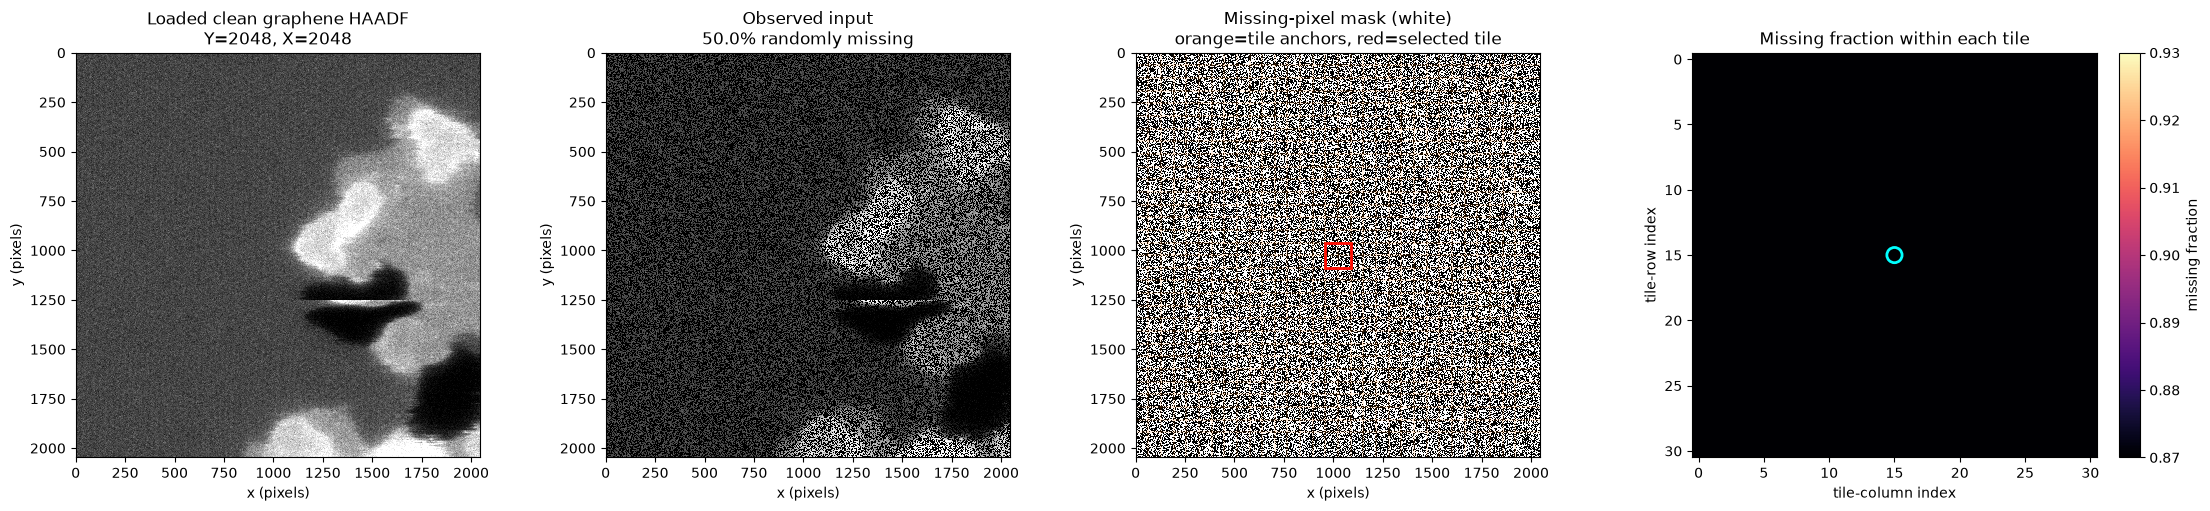

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/haadf_graphene_full_random_inpainting/graphene_2_Measurement_000/graphene_haadf_mask_and_tile_diagnostic.png


In [4]:
# Visualize the HDF5 frame, global observed input, pixel mask, and per-tile missingness.
fig, axes = plt.subplots(1, 4, figsize=(22, 5), constrained_layout=True)
axes[0].imshow(raw_haadf, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title(f'Loaded clean graphene HAADF\nY={height}, X={width}')
axes[1].imshow(observed_display, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[1].set_title(f'Observed input\n{missing_mask.mean():.1%} randomly missing')

axes[2].imshow(missing_mask, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
for top in tile_rows:
    axes[2].axhline(top, color='tab:orange', linewidth=0.3, alpha=0.5)
for left in tile_cols:
    axes[2].axvline(left, color='tab:orange', linewidth=0.3, alpha=0.5)
selected_top, selected_left = tile_locations[SELECTED_TILE_INDEX]
axes[2].add_patch(plt.Rectangle(
    (selected_left, selected_top), TILE_SIZE, TILE_SIZE,
    fill=False, edgecolor='red', linewidth=2.0,
))
axes[2].set_title('Missing-pixel mask (white)\norange=tile anchors, red=selected tile')

fraction_grid = tile_missing_fractions.reshape(len(tile_rows), len(tile_cols))
heatmap = axes[3].imshow(fraction_grid, cmap='magma', vmin=0.87, vmax=0.93, interpolation='nearest')
axes[3].scatter(
    [SELECTED_TILE_INDEX % len(tile_cols)], [SELECTED_TILE_INDEX // len(tile_cols)],
    facecolors='none', edgecolors='cyan', s=120, linewidths=2,
)
axes[3].set_title('Missing fraction within each tile')
axes[3].set_xlabel('tile-column index')
axes[3].set_ylabel('tile-row index')
fig.colorbar(heatmap, ax=axes[3], fraction=0.046, pad=0.04, label='missing fraction')
for axis in axes[:3]:
    axis.set_xlabel('x (pixels)')
    axis.set_ylabel('y (pixels)')

mask_figure_path = OUTPUT_DIR / 'graphene_haadf_mask_and_tile_diagnostic.png'
fig.savefig(mask_figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {mask_figure_path}')

In [5]:
@torch.inference_mode()
def pnp_flow_inpaint_tiles(observed, known):
    """Same Gaussian fixed-mask PnP-Flow update as the NFFA notebook."""
    known = known.to(device=observed.device, dtype=observed.dtype)
    x = known * observed
    lr = NOISE_STD ** 2 * LR_PNP
    for iteration in range(STEPS_PNP):
        t = torch.full((len(x),), iteration / STEPS_PNP, device=x.device)
        t_view = t.view(-1, 1, 1, 1)
        lr_t = lr * (1.0 - t).pow(ALPHA).view(-1, 1, 1, 1)
        data_gradient = known * (known * x - observed) / (NOISE_STD ** 2)
        z = x - lr_t * data_gradient
        x_new = torch.zeros_like(x)
        for _ in range(NUM_SAMPLES):
            z_tilde = t_view * z + (1.0 - t_view) * torch.randn_like(z)
            velocity = model(z_tilde, t)
            x_new += z_tilde + (1.0 - t_view) * velocity
        x_new /= NUM_SAMPLES
        x = known * observed + (1.0 - known) * x_new
    return x.clamp(-1.0, 1.0)

hann_1d = np.hanning(TILE_SIZE).astype(np.float32)
blend_window = np.outer(hann_1d, hann_1d)
blend_window = np.maximum(blend_window / blend_window.max(), 1e-3).astype(np.float32)

def extract_tiles(image):
    return np.stack([
        image[top:top + TILE_SIZE, left:left + TILE_SIZE]
        for top, left in tile_locations
    ])

print('PnP tile solver and Hann blending window are ready.')

PnP tile solver and Hann blending window are ready.


In [6]:
clean_tiles = extract_tiles(raw_norm).astype(np.float32)
observed_tiles = extract_tiles(observed_norm).astype(np.float32)
known_tiles = extract_tiles(known_mask).astype(np.float32)
missing_tiles = ~known_tiles.astype(bool)
restored_tiles = np.empty_like(clean_tiles, dtype=np.float32)

number_of_batches = math.ceil(len(tile_locations) / INFERENCE_BATCH_SIZE)
inference_start = time.perf_counter()
for batch_number, offset in enumerate(range(0, len(tile_locations), INFERENCE_BATCH_SIZE), start=1):
    stop = min(offset + INFERENCE_BATCH_SIZE, len(tile_locations))
    batch_observed = torch.from_numpy(observed_tiles[offset:stop, None]).to(device)
    batch_known = torch.from_numpy(known_tiles[offset:stop, None]).to(device)
    batch_start = time.perf_counter()
    restored_tiles[offset:stop] = pnp_flow_inpaint_tiles(batch_observed, batch_known).cpu().numpy()[:, 0]
    print(
        f'Completed tile batch {batch_number}/{number_of_batches}: tiles {offset}:{stop} '
        f'in {time.perf_counter() - batch_start:.1f} s'
    )
    del batch_observed, batch_known
    torch.cuda.empty_cache()

inference_seconds = time.perf_counter() - inference_start
print(f'All {len(tile_locations)} tiles reconstructed in {inference_seconds:.1f} s.')

reconstruction_sum = np.zeros_like(raw_norm, dtype=np.float32)
reconstruction_weight = np.zeros_like(raw_norm, dtype=np.float32)
for restored_tile, missing_tile, (top, left) in zip(restored_tiles, missing_tiles, tile_locations):
    target = np.s_[top:top + TILE_SIZE, left:left + TILE_SIZE]
    weights = blend_window * missing_tile.astype(np.float32)
    reconstruction_sum[target] += restored_tile * weights
    reconstruction_weight[target] += weights

uncovered = missing_mask & (reconstruction_weight <= 0)
if uncovered.any():
    raise RuntimeError(f'{uncovered.sum():,} missing pixels were not covered by a tile.')

reconstruction_norm = observed_norm.copy()
reconstruction_norm[missing_mask] = reconstruction_sum[missing_mask] / reconstruction_weight[missing_mask]
reconstruction_norm = np.clip(reconstruction_norm, -1.0, 1.0)
reconstruction_raw = denormalize(reconstruction_norm).astype(np.float32)
known_consistency = np.max(np.abs(reconstruction_norm[known_mask] - observed_norm[known_mask]))
print(f'Maximum known-pixel consistency error: {known_consistency:.3e}')
print(f'All {missing_mask.sum():,} missing pixels received blended predictions.')

Completed tile batch 1/2: tiles 0:640 in 1489.3 s
Completed tile batch 2/2: tiles 640:961 in 584.7 s
All 961 tiles reconstructed in 2074.2 s.
Maximum known-pixel consistency error: 0.000e+00
All 2,098,273 missing pixels received blended predictions.


In [7]:
clean_01 = (raw_norm + 1.0) * 0.5
observed_01 = (observed_norm + 1.0) * 0.5
reconstruction_01 = (reconstruction_norm + 1.0) * 0.5

def masked_psnr(reference, estimate, mask):
    mse = np.mean((reference[mask] - estimate[mask]) ** 2)
    return float(10.0 * np.log10(1.0 / max(float(mse), 1e-12)))

def full_psnr(reference, estimate):
    mse = np.mean((reference - estimate) ** 2)
    return float(10.0 * np.log10(1.0 / max(float(mse), 1e-12)))

metrics = {
    'h5_file': str(HAADF_H5),
    'h5_dataset': HAADF_DATASET_PATH,
    'height': int(height),
    'width': int(width),
    'physical_pixel_spacing_x': pixel_size_x,
    'physical_pixel_spacing_y': pixel_size_y,
    'normalization_low': float(low),
    'normalization_high': float(high),
    'missing_fraction': float(missing_mask.mean()),
    'tile_size': TILE_SIZE,
    'tile_stride': TILE_STRIDE,
    'tile_count': len(tile_locations),
    'steps_pnp': STEPS_PNP,
    'num_samples': NUM_SAMPLES,
    'alpha': ALPHA,
    'noise_std': NOISE_STD,
    'inference_seconds': float(inference_seconds),
    'observed_missing_psnr_db': masked_psnr(clean_01, observed_01, missing_mask),
    'reconstruction_missing_psnr_db': masked_psnr(clean_01, reconstruction_01, missing_mask),
    'reconstruction_full_psnr_db': full_psnr(clean_01, reconstruction_01),
    'missing_region_mae_normalized_01': float(np.mean(np.abs(clean_01[missing_mask] - reconstruction_01[missing_mask]))),
    'maximum_known_consistency_error': float(known_consistency),
}
try:
    from skimage.metrics import structural_similarity
    metrics['reconstruction_full_ssim'] = float(structural_similarity(clean_01, reconstruction_01, data_range=1.0))
except Exception as error:
    metrics['reconstruction_full_ssim'] = None
    print(f'SSIM was skipped: {error}')

for key, value in metrics.items():
    print(f'{key}: {value}')

np.save(OUTPUT_DIR / 'clean_haadf_float32.npy', raw_haadf.astype(np.float32))
np.save(OUTPUT_DIR / 'observed_normalized_float32.npy', observed_norm.astype(np.float32))
np.save(OUTPUT_DIR / 'missing_mask_uint8.npy', missing_mask.astype(np.uint8))
np.save(OUTPUT_DIR / 'reconstruction_normalized_float32.npy', reconstruction_norm.astype(np.float32))
np.save(OUTPUT_DIR / 'reconstruction_haadf_float32.npy', reconstruction_raw.astype(np.float32))
with (OUTPUT_DIR / 'metrics.json').open('w', encoding='utf-8') as handle:
    json.dump(metrics, handle, indent=2)
print(f'Saved arrays and metrics to: {OUTPUT_DIR}')

h5_file: /home/bselvaku/projects/microscopic_inpainting/content/graphene_2.h5
h5_dataset: Measurement_000/Channel_000/HAADF/HAADF
height: 2048
width: 2048
physical_pixel_spacing_x: 0.007511111652003688
physical_pixel_spacing_y: 0.007511111652003688
normalization_low: 4917.0
normalization_high: 48564.0
missing_fraction: 0.5002672672271729
tile_size: 128
tile_stride: 64
tile_count: 961
steps_pnp: 100
num_samples: 5
alpha: 0.01
noise_std: 0.01
inference_seconds: 2074.21764665097
observed_missing_psnr_db: 12.080931933397414
reconstruction_missing_psnr_db: 24.78124127533475
reconstruction_full_psnr_db: 27.757133274393382
missing_region_mae_normalized_01: 0.04525778442621231
maximum_known_consistency_error: 0.0
reconstruction_full_ssim: 0.7187651822475105
Saved arrays and metrics to: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/haadf_graphene_full_random_inpainting/graphene_2_Measurement_000


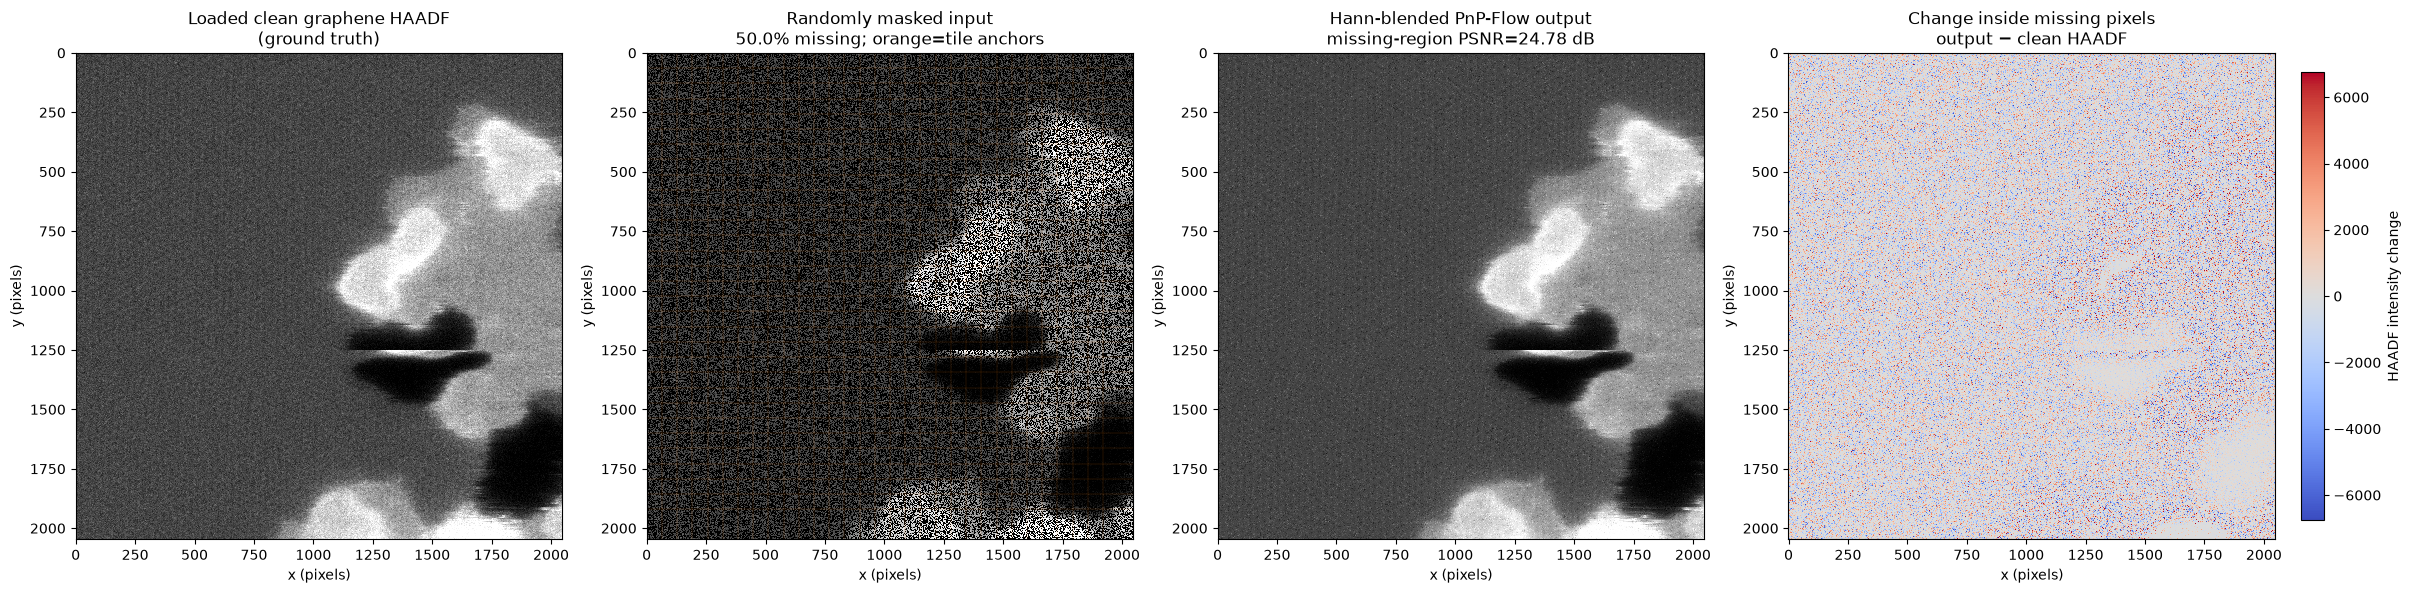

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/haadf_graphene_full_random_inpainting/graphene_2_Measurement_000/graphene_haadf_full_frame_four_panel_comparison.png


In [8]:
# Full-frame comparison: clean HDF5 frame, masked input, reconstruction, and change.
change_inside_mask = np.zeros_like(raw_haadf, dtype=np.float32)
change_inside_mask[missing_mask] = reconstruction_raw[missing_mask] - raw_clipped[missing_mask]
change_limit = max(float(np.percentile(np.abs(change_inside_mask[missing_mask]), 99)), 1e-6)

fig, axes = plt.subplots(1, 4, figsize=(24, 6), constrained_layout=True)
axes[0].imshow(raw_haadf, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title('Loaded clean graphene HAADF\n(ground truth)')
axes[1].imshow(observed_display, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
for top in tile_rows:
    axes[1].axhline(top, color='tab:orange', linewidth=0.25, alpha=0.4)
for left in tile_cols:
    axes[1].axvline(left, color='tab:orange', linewidth=0.25, alpha=0.4)
axes[1].set_title(f'Randomly masked input\n{missing_mask.mean():.1%} missing; orange=tile anchors')
axes[2].imshow(reconstruction_raw, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[2].set_title(
    'Hann-blended PnP-Flow output\n'
    f"missing-region PSNR={metrics['reconstruction_missing_psnr_db']:.2f} dB"
)
change_plot = axes[3].imshow(
    change_inside_mask, cmap='coolwarm', vmin=-change_limit, vmax=change_limit,
    interpolation='nearest',
)
axes[3].set_title('Change inside missing pixels\noutput − clean HAADF')
fig.colorbar(change_plot, ax=axes[3], fraction=0.046, pad=0.04, label='HAADF intensity change')
for axis in axes:
    axis.set_xlabel('x (pixels)')
    axis.set_ylabel('y (pixels)')

comparison_path = OUTPUT_DIR / 'graphene_haadf_full_frame_four_panel_comparison.png'
fig.savefig(comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {comparison_path}')

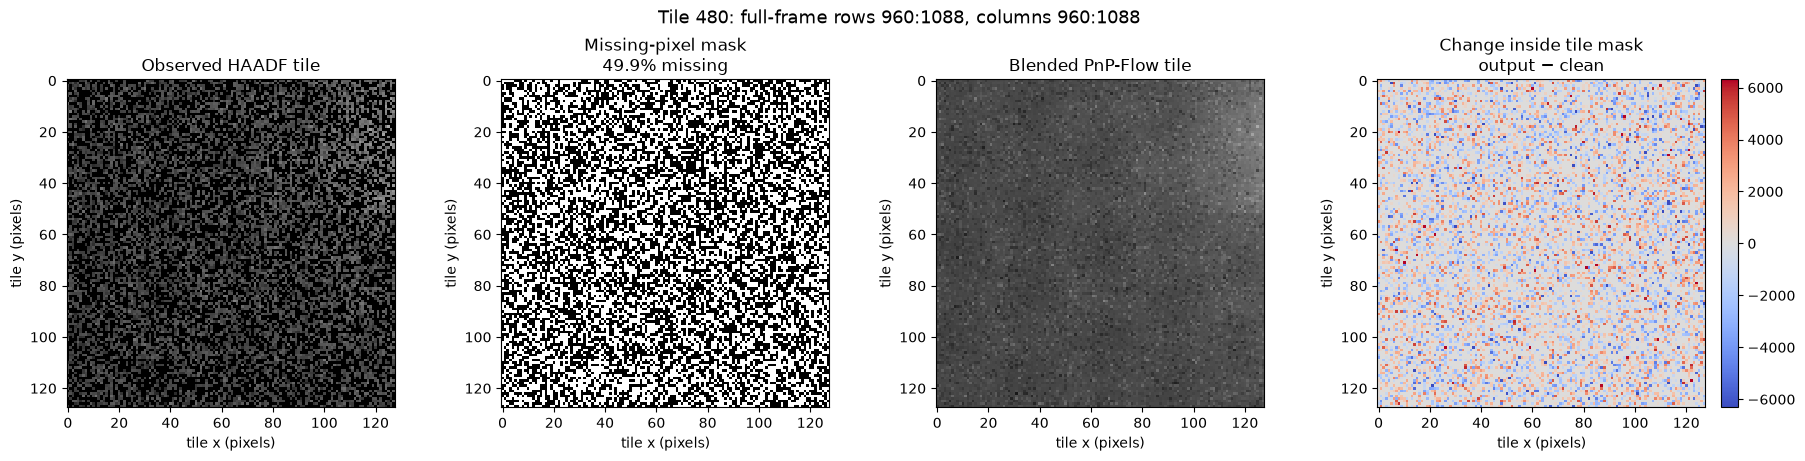

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/haadf_graphene_full_random_inpainting/graphene_2_Measurement_000/graphene_haadf_tile_480_four_panel_comparison.png


In [9]:
# Selectable per-tile four-panel comparison.
tile_top, tile_left = tile_locations[SELECTED_TILE_INDEX]
tile_slice = np.s_[tile_top:tile_top + TILE_SIZE, tile_left:tile_left + TILE_SIZE]
selected_missing = missing_mask[tile_slice]
selected_observed = observed_display[tile_slice]
selected_reconstruction = reconstruction_raw[tile_slice]
selected_clean = raw_clipped[tile_slice]
selected_change = np.zeros((TILE_SIZE, TILE_SIZE), dtype=np.float32)
selected_change[selected_missing] = selected_reconstruction[selected_missing] - selected_clean[selected_missing]
selected_limit = max(float(np.percentile(np.abs(selected_change[selected_missing]), 99)), 1e-6)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)
axes[0].imshow(selected_observed, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title('Observed HAADF tile')
axes[1].imshow(selected_missing, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
axes[1].set_title(f'Missing-pixel mask\n{selected_missing.mean():.1%} missing')
axes[2].imshow(selected_reconstruction, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[2].set_title('Blended PnP-Flow tile')
tile_change_plot = axes[3].imshow(
    selected_change, cmap='coolwarm', vmin=-selected_limit, vmax=selected_limit,
    interpolation='nearest',
)
axes[3].set_title('Change inside tile mask\noutput − clean')
fig.colorbar(tile_change_plot, ax=axes[3], fraction=0.046, pad=0.04)
for axis in axes:
    axis.set_xlabel('tile x (pixels)')
    axis.set_ylabel('tile y (pixels)')
fig.suptitle(
    f'Tile {SELECTED_TILE_INDEX}: full-frame rows {tile_top}:{tile_top + TILE_SIZE}, '
    f'columns {tile_left}:{tile_left + TILE_SIZE}',
    fontsize=13,
)

tile_path = OUTPUT_DIR / f'graphene_haadf_tile_{SELECTED_TILE_INDEX:03d}_four_panel_comparison.png'
fig.savefig(tile_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {tile_path}')

## Runtime note

At 2048 × 2048, tile size 128, and stride 64, this frame requires 961 tile reconstructions. With 100 PnP steps and 5 prior samples per step, a complete run is substantially longer than the 768 × 1024 NFFA benchmark.